# Case study 2 · Binary ANN: will an airline passenger be satisfied?

**Course file:** `../course-files/Case_Study_ANN_Airline_Passenger_Satisfaction.pdf` (the class's Colab notebook) · **Data:** `data/airline_passenger_satisfaction.csv` (103,904 passengers, 25 columns)

This notebook **reproduces the class case study** (same encoding, split, scaler, model, optimizer, epochs and batch size), explains each step, and then adds what a careful analyst checks: baselines, longer training, the decision threshold, which features drive the predictions, and a tree-ensemble comparison.

**The question:** from a passenger's profile (age, loyalty, travel type, class, flight distance), their 1–5 ratings of 14 services (wifi, seat comfort, online boarding, …) and the delays, predict **satisfied** vs **neutral or dissatisfied**.

What changes compared with the multi-class case study:

| | Forest cover (case study 1) | Airline satisfaction (this one) |
|---|---|---|
| classes | 7 (one of them) | 2 (yes / no) |
| output layer | 7 units, **softmax** | **1 unit, sigmoid** |
| loss | sparse categorical cross-entropy | **binary cross-entropy** |
| prediction | argmax of 7 probabilities | probability ≥ **threshold** (0.5 by default) |
| extra work | none | **text columns to encode**, **missing values**, **ID columns to drop** |

Keras 3 with the PyTorch backend, as in class. Runs in about 4–5 minutes on a laptop CPU.

In [1]:
%matplotlib inline
import os, time
os.environ.setdefault("KERAS_BACKEND", "torch")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, classification_report)
import keras
from keras import layers, models, callbacks
np.random.seed(42); keras.utils.set_random_seed(42)
print("Keras", keras.__version__, "| backend:", keras.backend.backend())

Keras 3.13.2 | backend: torch


## 1 · Load and inspect

In [2]:
df = pd.read_csv("data/airline_passenger_satisfaction.csv")
print(f"{df.shape[0]:,} rows × {df.shape[1]} columns\n")
print(df.dtypes.value_counts().to_string(), "\n")
print("text columns:", df.select_dtypes(exclude="number").columns.tolist())
print("\nmissing values:\n" + df.isnull().sum()[df.isnull().sum() > 0].to_string())
print("\ntarget balance:\n" + df["satisfaction"].value_counts(normalize=True).round(4).to_string())
df.head(3)

103,904 rows × 25 columns

int64      19
str         5
float64     1 

text columns: ['Gender', 'Customer Type', 'Type of Travel', 'Class', 'satisfaction']

missing values:
Arrival Delay in Minutes    310

target balance:
satisfaction
neutral or dissatisfied    0.5667
satisfied                  0.4333


,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied


- **103,904 passengers**, 25 columns: 19 integer, 1 decimal, 5 text (Gender, Customer Type, Type of Travel, Class and the target).
- **Target balance:** 56.7% "neutral or dissatisfied", 43.3% "satisfied". That's reasonably balanced, so accuracy is a fair headline metric here (unlike the forest data).
- **Only one column has missing values:** Arrival Delay (310 rows, 0.3%).

### Things to fix before any model sees the data

In [3]:
print("'Unnamed: 0' is just 0, 1, 2, ...:", bool((df["Unnamed: 0"] == np.arange(len(df))).all()))
print("'id' is unique for every row:", df["id"].is_unique)
ratings = ["Inflight wifi service", "Departure/Arrival time convenient", "Ease of Online booking", "Gate location",
           "Food and drink", "Online boarding", "Seat comfort", "Inflight entertainment", "On-board service",
           "Leg room service", "Baggage handling", "Checkin service", "Inflight service", "Cleanliness"]
zeros = (df[ratings] == 0).sum()
print("\nratings equal to 0 (outside the 1-5 scale = 'not rated / not applicable'):\n" + zeros[zeros > 0].to_string())
print(f"\ncorrelation between departure and arrival delay: {df['Departure Delay in Minutes'].corr(df['Arrival Delay in Minutes']):.3f}")

'Unnamed: 0' is just 0, 1, 2, ...: True
'id' is unique for every row: True

ratings equal to 0 (outside the 1-5 scale = 'not rated / not applicable'):
Inflight wifi service                3103
Departure/Arrival time convenient    5300
Ease of Online booking               4487
Gate location                           1
Food and drink                        107
Online boarding                      2428
Seat comfort                            1
Inflight entertainment                 14
On-board service                        3
Leg room service                      472
Checkin service                         1
Inflight service                        3
Cleanliness                            12

correlation between departure and arrival delay: 0.965


- **`Unnamed: 0` and `id` are identifiers, not information.** A row number can't cause satisfaction; keeping them invites the network to memorise noise. **Drop both.**
- **Ratings of 0** sit outside the 1–5 scale: the passenger didn't rate that service (e.g. no wifi on board). We keep them as they are (0 = "not rated"); a tree or a network can learn that 0 means something different. *(A careful alternative: add a "not rated" flag.)*
- **Arrival delay has 310 missing values.** It's almost the same as the departure delay (correlation printed above), so filling the gaps with the **median of the training set** is a safe, simple choice. Filling must happen **after** the split, using training statistics only, like scaling.

## 2 · Explore: what goes with satisfaction?

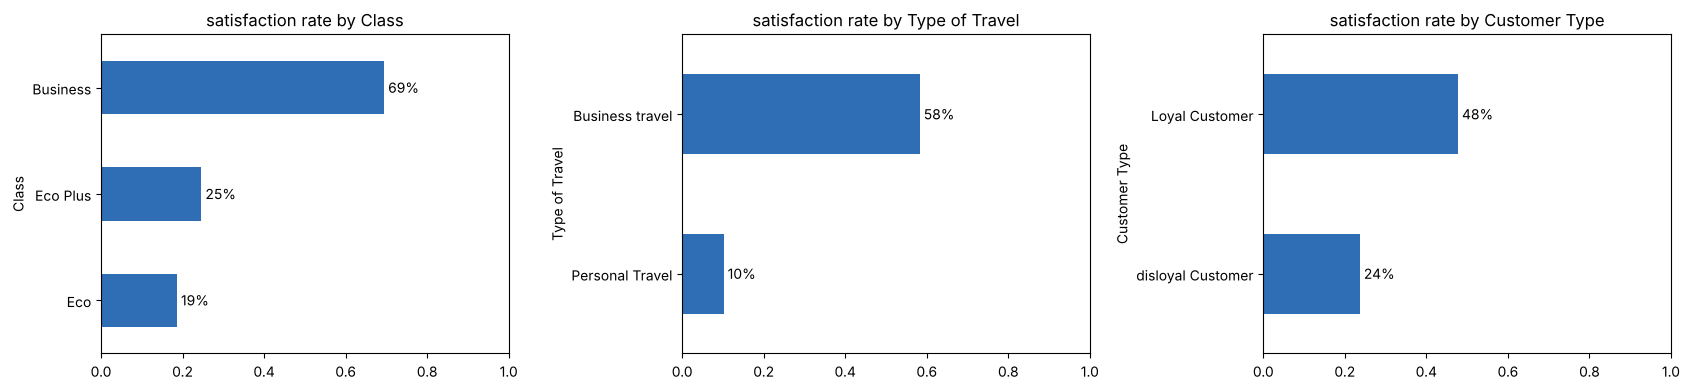

correlation of each numeric column with being satisfied:
Online boarding                      0.504
Inflight entertainment               0.398
Seat comfort                         0.349
On-board service                     0.322
Leg room service                     0.313
Cleanliness                          0.305
Flight Distance                      0.299
Inflight wifi service                0.284
Baggage handling                     0.248
Inflight service                     0.245
Checkin service                      0.236
Food and drink                       0.210
Ease of Online booking               0.172
Age                                  0.137
Gate location                        0.001
Departure Delay in Minutes          -0.050
Departure/Arrival time convenient   -0.052


In [4]:
df["satisfied"] = (df["satisfaction"] == "satisfied").astype(int)
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, col in zip(axes, ["Class", "Type of Travel", "Customer Type"]):
    rate = df.groupby(col)["satisfied"].mean().sort_values()
    rate.plot.barh(ax=ax, color="#2f6db5"); ax.set_xlim(0, 1); ax.set_title(f"satisfaction rate by {col}")
    for i, v in enumerate(rate): ax.text(v + 0.01, i, f"{v:.0%}", va="center")
plt.tight_layout(); plt.show()

corr = df[ratings + ["Age", "Flight Distance", "Departure Delay in Minutes"]].corrwith(df["satisfied"]).sort_values(ascending=False)
print("correlation of each numeric column with being satisfied:\n" + corr.round(3).to_string())

**What the plots and correlations say:**
- **Travel type and class matter a lot:** business travellers are satisfied 58% of the time, personal travellers only 10%; Business class 69% vs Eco 19%.
- **Online boarding** has the strongest linear link (correlation 0.50), then inflight entertainment (0.40) and seat comfort (0.35).
- **Delays barely correlate** (−0.05): annoying, but not what decides satisfaction overall.
- **Careful: correlation only measures straight-line relationships.** Wifi correlates only 0.28, yet its satisfaction rate is **U-shaped**: rating 0 (not rated) → 99.7% satisfied, ratings 2–3 → about 25%, rating 5 → 99.1%. Gate location correlates 0.001 but also varies (35% at rating 3, 57% at rating 5). A straight line can't capture a U, but a neural network can (section 7 confirms it).

## 3 · Encode, split, impute, scale
Exactly as in the class notebook: the target becomes 1 = satisfied / 0 = neutral or dissatisfied, and the 4 text columns are one-hot encoded with `drop_first=True`. A two-valued column becomes **one** 0/1 column; **Class** (Business, Eco, Eco Plus) becomes **two** columns (Eco, Eco Plus), with Business as the "all zeros" reference. Never 0/1/2: that would invent an order and equal distances between classes.

*One improvement over the class notebook:* it filled the missing delays with the median of **all** rows **before** splitting. Here the median comes from the **training** rows only, after the split, so no test information leaks in. (The value is 0.0 minutes either way, so the results are unaffected.)

In [5]:
data = df.drop(columns=["Unnamed: 0", "id", "satisfaction"])            # 'satisfied' (0/1) was created above
cat_cols = data.select_dtypes(exclude="number").columns.tolist()
print(f"categorical features to encode ({len(cat_cols)}): {cat_cols}")
data = pd.get_dummies(data, columns=cat_cols, drop_first=True, dtype=float)
X = data.drop(columns=["satisfied"]); y = data["satisfied"].values
print(f"{X.shape[1]} features; the encoded ones: {[c for c in X.columns if '_' in c]}")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
median_delay = X_train["Arrival Delay in Minutes"].median()              # statistic from TRAIN only
X_train = X_train.fillna({"Arrival Delay in Minutes": median_delay}); X_test = X_test.fillna({"Arrival Delay in Minutes": median_delay})
print(f"filled missing arrival delays with the training median = {median_delay} min; remaining NaNs: {int(X_train.isnull().sum().sum() + X_test.isnull().sum().sum())}")

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train); X_test_s = scaler.transform(X_test)
print(f"train {X_train_s.shape}, test {X_test_s.shape}")

categorical features to encode (4): ['Gender', 'Customer Type', 'Type of Travel', 'Class']
23 features; the encoded ones: ['Gender_Male', 'Customer Type_disloyal Customer', 'Type of Travel_Personal Travel', 'Class_Eco', 'Class_Eco Plus']


filled missing arrival delays with the training median = 0.0 min; remaining NaNs: 0


train (83123, 23), test (20781, 23)


## 4 · Baselines first

In [6]:
print(f"always 'not satisfied' (majority class): accuracy {np.mean(y_test == 0):.2%}")
logreg = LogisticRegression(max_iter=2000).fit(X_train_s, y_train)
p_lr = logreg.predict_proba(X_test_s)[:, 1]
print(f"logistic regression: accuracy {accuracy_score(y_test, p_lr >= 0.5):.2%}, ROC AUC {roc_auc_score(y_test, p_lr):.4f}")

always 'not satisfied' (majority class): accuracy 56.67%


logistic regression: accuracy 87.64%, ROC AUC 0.9281


A **logistic regression** is exactly a single sigmoid neuron (chapter 02/03) trained with BCE. It's the natural baseline: the ANN must beat **one neuron** to justify its hidden layers.

## 5 · The ANN
Same building blocks as case study 1, with a **1-unit sigmoid output** and **binary cross-entropy**.

In [7]:
def build_model():                                   # the class notebook's architecture
    return models.Sequential([
        layers.Input(shape=(X_train_s.shape[1],)),
        layers.Dense(64, activation="relu", name="dense_1"),
        layers.BatchNormalization(name="batch_norm_1"),
        layers.Dropout(0.20, name="dropout_1"),
        layers.Dense(32, activation="relu", name="dense_2"),
        layers.Dropout(0.10, name="dropout_2"),
        layers.Dense(16, activation="relu", name="dense_3"),
        layers.Dense(1, activation="sigmoid", name="output_layer"),
    ])

def fit(epochs):
    keras.utils.set_random_seed(42)
    m = build_model()
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss="binary_crossentropy", metrics=["accuracy"])
    t0 = time.time()
    hist = m.fit(X_train_s, y_train, validation_split=0.20, epochs=epochs, batch_size=128, verbose=0,
                 callbacks=[callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)])
    return m, hist.history, time.time() - t0

model, h, secs = fit(15)                             # the class settings: 15 epochs, batch 128
model.summary()
best = int(np.argmin(h["val_loss"]))
print(f"66,498 training rows / batch 128 = {int(np.ceil(66498 / 128))} updates per epoch")
print(f"trained {len(h['loss'])} epochs in {secs:.0f} s; best val_loss {h['val_loss'][best]:.4f} at epoch {best + 1} (val acc {h['val_accuracy'][best]:.4f})")
for e in [0, 4, 9, len(h["loss"]) - 1]:
    print(f"epoch {e + 1:>2}: train acc {h['accuracy'][e]:.4f} loss {h['loss'][e]:.4f} | val acc {h['val_accuracy'][e]:.4f} loss {h['val_loss'][e]:.4f}")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 64)             │         1,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_norm_1                    │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,997 (50.77 KB)

 Trainable params: 4,289 (16.75 KB)

 Non-trainable params: 128 (512.00 B)

 Optimizer params: 8,580 (33.52 KB)

66,498 training rows / batch 128 = 520 updates per epoch
trained 15 epochs in 82 s; best val_loss 0.1017 at epoch 15 (val acc 0.9566)
epoch  1: train acc 0.8890 loss 0.2712 | val acc 0.9250 loss 0.1763
epoch  5: train acc 0.9418 loss 0.1404 | val acc 0.9504 loss 0.1215
epoch 10: train acc 0.9504 loss 0.1176 | val acc 0.9554 loss 0.1062
epoch 15: train acc 0.9543 loss 0.1084 | val acc 0.9566 loss 0.1017


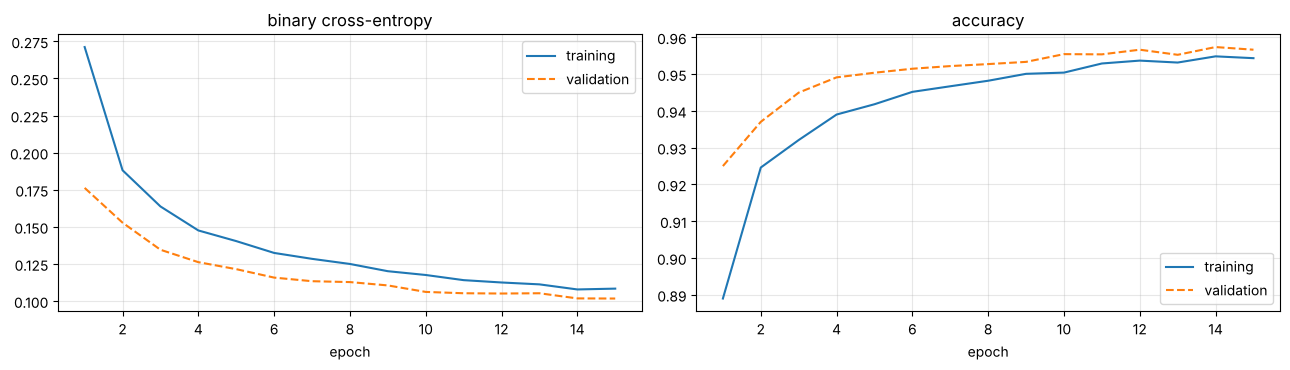

In [8]:
ep = range(1, len(h["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(ep, h["loss"], label="training"); axes[0].plot(ep, h["val_loss"], "--", label="validation"); axes[0].set_title("binary cross-entropy")
axes[1].plot(ep, h["accuracy"], label="training"); axes[1].plot(ep, h["val_accuracy"], "--", label="validation"); axes[1].set_title("accuracy")
for ax in axes: ax.set_xlabel("epoch"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 6 · Evaluate on the test set

accuracy 95.85% | precision 97.17% | recall 93.13% | F1 95.11% | ROC AUC 0.9939

                      precision    recall  f1-score   support

neutral/dissatisfied     0.9491    0.9793    0.9639     11776
           satisfied     0.9717    0.9313    0.9511      9005

            accuracy                         0.9585     20781
           macro avg     0.9604    0.9553    0.9575     20781
        weighted avg     0.9589    0.9585    0.9584     20781



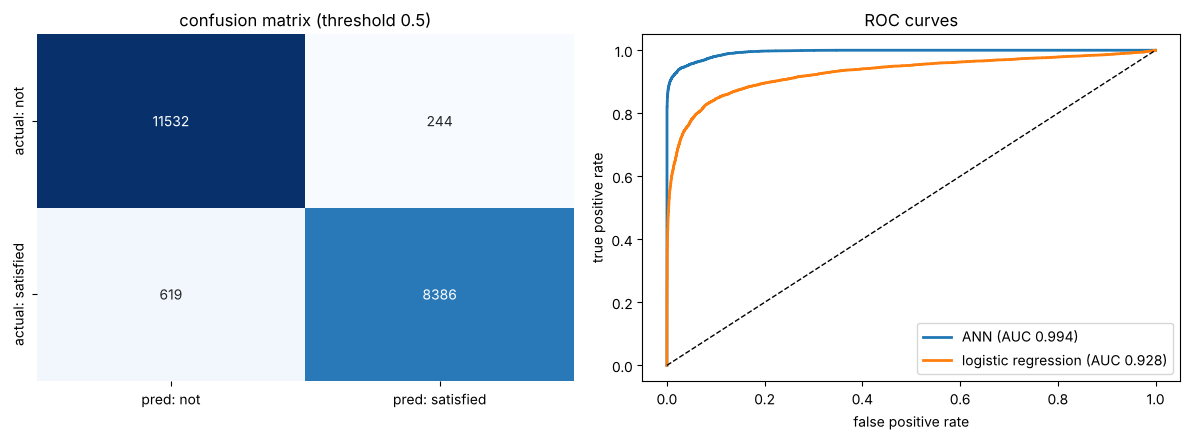

In [9]:
p_ann = model.predict(X_test_s, verbose=0).ravel()
y_hat = (p_ann >= 0.5).astype(int)
print(f"accuracy {accuracy_score(y_test, y_hat):.2%} | precision {precision_score(y_test, y_hat):.2%} | recall {recall_score(y_test, y_hat):.2%} | F1 {f1_score(y_test, y_hat):.2%} | ROC AUC {roc_auc_score(y_test, p_ann):.4f}")
print()
print(classification_report(y_test, y_hat, target_names=["neutral/dissatisfied", "satisfied"], digits=4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.heatmap(confusion_matrix(y_test, y_hat), annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["pred: not", "pred: satisfied"], yticklabels=["actual: not", "actual: satisfied"])
axes[0].set_title("confusion matrix (threshold 0.5)")
for name, pr in [("ANN", p_ann), ("logistic regression", p_lr)]:
    fpr, tpr, _ = roc_curve(y_test, pr); axes[1].plot(fpr, tpr, lw=2, label=f"{name} (AUC {roc_auc_score(y_test, pr):.3f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=1); axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate")
axes[1].legend(); axes[1].set_title("ROC curves")
plt.tight_layout(); plt.show()

**The reproduction matches the class notebook:**

| | class PDF | this run |
|---|---|---|
| accuracy | 95.83% | **95.85%** |
| precision | 96.79% | 97.17% |
| recall | 93.48% | 93.13% |
| F1 | 95.11% | 95.11% |
| ROC AUC | 0.9936 | 0.9939 |

Tiny differences come from random initialisation and hardware.

**Reading the results:**
- Against the **56.7%** majority baseline and **87.6%** for logistic regression (one sigmoid neuron, AUC 0.928), the hidden layers add **+8.2 points**. That fits the EDA: the important relationships are **non-linear** (the U-shaped wifi effect, interactions like "personal trip in Eco").
- **Precision 97.2%** (when it says "satisfied" it's almost always right) vs **recall 93.1%** (it misses about 7% of the satisfied passengers). Its mistakes lean towards under-calling satisfaction, as in the class confusion matrix (587 false negatives vs 279 false positives).
- **Validation accuracy stays above training accuracy** (0.957 vs 0.954 at epoch 15): dropout is active when training accuracy is measured.

> **Note on the class PDF:** its printed training log starts at 0.954 accuracy in epoch 1, but its loss/accuracy plot starts at about 0.887. Our epoch 1 is **0.889 (loss 0.271)**, matching the **plot**. So the log comes from a re-run on an already-trained model, which also explains the PDF's "Dropped non-predictive columns: []" line (the columns had already been dropped in an earlier run of that cell). It's the same plot/log mismatch as in the forest case study, and a good reason to **restart and run all** before trusting a notebook.

### Would more epochs help?
The class run's best epoch was its **last** one (15), so early stopping never triggered. Same model, same seed, but up to 40 epochs:

In [10]:
model40, h40, secs40 = fit(40)
best40 = int(np.argmin(h40["val_loss"]))
p40 = model40.predict(X_test_s, verbose=0).ravel()
print(f"ran {len(h40['loss'])} epochs ({secs40:.0f} s); best val_loss {h40['val_loss'][best40]:.4f} at epoch {best40 + 1}")
print(f"test accuracy {accuracy_score(y_test, p40 >= 0.5):.2%} (15 epochs: {accuracy_score(y_test, p_ann >= 0.5):.2%}) | ROC AUC {roc_auc_score(y_test, p40):.4f}")

ran 34 epochs (182 s); best val_loss 0.0954 at epoch 29
test accuracy 96.03% (15 epochs: 95.85%) | ROC AUC 0.9944


With room to keep going, the model improved until **epoch 29** (val loss 0.0954 vs 0.1017 at epoch 15), then early stopping ended training at epoch 34 and restored epoch 29's weights. Test accuracy went **95.85% → 96.03%**: a small but real gain. **When the best epoch is the last epoch, the run was cut short.** Allow more epochs and let early stopping decide.

### The threshold is a choice, not a law
The sigmoid outputs a probability; **0.5 is only the default cut-off**. If the airline wants to find as many unhappy passengers as possible (to contact them), it might lower the bar for "not satisfied". Watch precision and recall trade off:

In [11]:
print(f"{'threshold':>9} {'precision':>10} {'recall':>8} {'F1':>7} {'accuracy':>9}   (for the 'satisfied' class)")
for t in [0.2, 0.35, 0.5, 0.65, 0.8]:
    yh = (p_ann >= t).astype(int)
    print(f"{t:>9} {precision_score(y_test, yh):>10.3f} {recall_score(y_test, yh):>8.3f} {f1_score(y_test, yh):>7.3f} {accuracy_score(y_test, yh):>9.3f}")

threshold  precision   recall      F1  accuracy   (for the 'satisfied' class)
      0.2      0.879    0.982   0.928     0.934
     0.35      0.950    0.949   0.949     0.956
      0.5      0.972    0.931   0.951     0.958
     0.65      0.987    0.910   0.947     0.956
      0.8      0.994    0.887   0.937     0.949


- Threshold **0.2:** recall 0.982 (finds nearly every satisfied passenger) but precision falls to 0.879.
- Threshold **0.8:** precision 0.994 but recall 0.887.
- Accuracy and F1 peak around **0.35–0.5**, so the default is sensible here. Choose the threshold by the **cost of each kind of mistake**, not by habit.

## 7 · Which features drive the predictions? (permutation importance)
Shuffle one column in the test set (breaking its link with the answer) and measure how much accuracy drops. A big drop = the model relies on that feature.

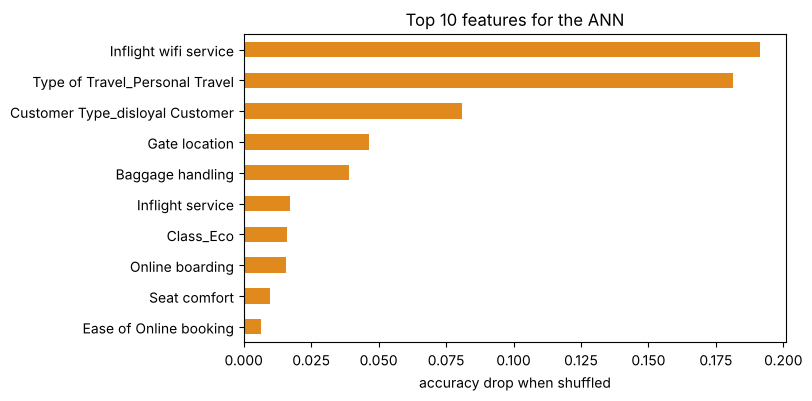

Inflight wifi service              0.1915
Type of Travel_Personal Travel     0.1813
Customer Type_disloyal Customer    0.0810
Gate location                      0.0463
Baggage handling                   0.0390
Inflight service                   0.0170
Class_Eco                          0.0159
Online boarding                    0.0156


In [12]:
rng = np.random.default_rng(0)
sub = rng.choice(len(X_test_s), 8000, replace=False)
Xs, ys = X_test_s[sub], y_test[sub]
base = accuracy_score(ys, model.predict(Xs, verbose=0).ravel() >= 0.5)
drops = {}
for j, col in enumerate(X.columns):
    Xp = Xs.copy(); Xp[:, j] = rng.permutation(Xp[:, j])
    drops[col] = base - accuracy_score(ys, model.predict(Xp, verbose=0).ravel() >= 0.5)
imp = pd.Series(drops).sort_values(ascending=False)
imp.head(10).iloc[::-1].plot.barh(figsize=(7, 4), color="#e08a1e"); plt.xlabel("accuracy drop when shuffled"); plt.title("Top 10 features for the ANN"); plt.show()
print(imp.head(8).round(4).to_string())

**What the network relies on:** shuffling **Inflight wifi** drops accuracy by **19 points**, **Type of Travel (personal)** by 18, Customer Type (disloyal) by 8, and **Gate location** by 5. Wifi and gate location have **weak correlations** with satisfaction (0.28 and 0.001), yet they're among the most important features to the network, because it uses their **non-linear** (U-shaped) patterns. **Correlation ≠ importance.**

*Caution:* permutation importance shows what **this model** uses, not what **causes** satisfaction, and correlated features can share or hide each other's importance.

## 8 · A random forest for comparison

In [13]:
t0 = time.time()
rf = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42).fit(X_train, y_train)
p_rf = rf.predict_proba(X_test)[:, 1]
print(f"random forest: {time.time() - t0:.0f} s | accuracy {accuracy_score(y_test, p_rf >= 0.5):.2%} | ROC AUC {roc_auc_score(y_test, p_rf):.4f}")

random forest: 5 s | accuracy 96.20% | ROC AUC 0.9940


## 9 · Predict for new passengers (the class notebook's two profiles)
The class PDF is cut off part-way through profile 2. Its remaining fields (inflight service, cleanliness, delays) are filled in here with values matching the profile's "delighted" pattern: 5, 5, 0 and 0.

In [14]:
profiles = [
    {"Gender": "Female", "Customer Type": "Loyal Customer", "Age": 32, "Type of Travel": "Personal Travel", "Class": "Eco",
     "Flight Distance": 1200, "Inflight wifi service": 1, "Departure/Arrival time convenient": 2, "Ease of Online booking": 1,
     "Gate location": 3, "Food and drink": 1, "Online boarding": 2, "Seat comfort": 1, "Inflight entertainment": 1,
     "On-board service": 2, "Leg room service": 1, "Baggage handling": 2, "Checkin service": 2, "Inflight service": 2,
     "Cleanliness": 1, "Departure Delay in Minutes": 75, "Arrival Delay in Minutes": 82.0},
    {"Gender": "Male", "Customer Type": "Loyal Customer", "Age": 45, "Type of Travel": "Business travel", "Class": "Business",
     "Flight Distance": 2500, "Inflight wifi service": 5, "Departure/Arrival time convenient": 4, "Ease of Online booking": 5,
     "Gate location": 4, "Food and drink": 5, "Online boarding": 5, "Seat comfort": 5, "Inflight entertainment": 5,
     "On-board service": 5, "Leg room service": 5, "Baggage handling": 5, "Checkin service": 5, "Inflight service": 5,
     "Cleanliness": 5, "Departure Delay in Minutes": 0, "Arrival Delay in Minutes": 0.0},
]
new = pd.get_dummies(pd.DataFrame(profiles), columns=cat_cols, dtype=float).reindex(columns=X.columns, fill_value=0.0)
for name, p_ in zip(["Profile 1: discontented Eco traveller", "Profile 2: delighted Business traveller"],
                    model.predict(scaler.transform(new), verbose=0).ravel()):
    print(f"{name:<40} P(satisfied) = {p_:6.1%}  ->  {'SATISFIED' if p_ >= 0.5 else 'NEUTRAL / DISSATISFIED'}")

Profile 1: discontented Eco traveller    P(satisfied) =   0.0%  ->  NEUTRAL / DISSATISFIED
Profile 2: delighted Business traveller  P(satisfied) = 100.0%  ->  SATISFIED


## 10 · Summary

| Model | Test accuracy | ROC AUC |
|---|---|---|
| always "not satisfied" | 56.67% | n/a |
| logistic regression (one sigmoid neuron) | 87.64% | 0.928 |
| **class ANN, 15 epochs** (this run) | **95.85%** | **0.994** |
| class ANN (class PDF run) | 95.83% | 0.994 |
| class ANN, up to 40 epochs (stopped at 34, best 29) | 96.03% | 0.994 |
| random forest (200 trees, 5 s) | 96.20% | 0.994 |

The class model's predictions for the two new profiles are clear-cut: the discontented Eco traveller gets **P(satisfied) ≈ 0%**, the delighted Business traveller **≈ 100%**.

**Lessons:**
1. **Clean before modelling:** drop identifiers, one-hot encode categories (`drop_first=True` keeps k − 1 columns), impute and scale **using training statistics only**.
2. **Baselines tell you what the model adds:** hidden layers gave +8.2 points over logistic regression, because the patterns are non-linear.
3. **Binary = 1 sigmoid unit + binary cross-entropy**, and the **threshold** is a business decision.
4. **If the best epoch is the last one, train longer** (+0.2 points here).
5. **Correlation misses non-linear effects**; permutation importance on the trained model reveals them.
6. The ANN and the random forest **tie** on this table. As in case study 1, always compare with a tree ensemble on tabular data.
7. **Restart and run all** before trusting a notebook: the class PDF's log and plot come from different runs.

## ✅ Check yourself
1. Why drop `id` and `Unnamed: 0`? *(identifiers carry no information; the model could memorise noise)*
2. Why one-hot encode Class instead of 0/1/2? And why does `drop_first=True` leave only 2 Class columns? *(0/1/2 would invent an order and equal spacing; the dropped category, Business, is the case where both remaining columns are 0)*
3. Why impute the missing delays with the **training** median? *(using test statistics leaks information)*
4. Output layer and loss for a binary problem? *(1 sigmoid unit + binary cross-entropy)*
5. Logistic regression = which neural network? *(a single sigmoid neuron, no hidden layer)*
6. Lowering the threshold from 0.5 to 0.2 for "satisfied": what happens to recall and precision? *(recall up, precision down)*
7. What does permutation importance measure? *(how much the score drops when one feature's link with the target is destroyed)*